This file contains code for our extension project, which is a program designed to dynamically adjust to user-specified preferences in prioritizing factors for the installation of new water filling stations. The program intelligently assimilates a factor chosen by the user—such as foot traffic, proximity to existing facilities, or any other relevant criterion—and recalibrates the prioritization algorithm accordingly to generate an optimized list of potential installation sites.


Parts of this file:

1.  **Setup and Data Importing:**
Initializes the notebook environment and loads the extension_data.csv dataset, which contains data for potential locations for water filling stations on Boston University's campus.
2.  **Function Definition for Custom Prioritization:**
Defines a function prioritize_specified_factor which takes a user-defined factor for prioritization (e.g., Foot Traffic, Existing Stations) and adjusts the prioritization algorithm accordingly.
3.  **Dynamic Adjustment of Weights and Scores:**
Dynamically adjusts the weighting of each factor based on user input to emphasize the chosen factor more heavily in the prioritization process.
Calculates a new score for each potential location by combining these weights with the normalized data values.
4.  **Generation and Output of Prioritized List:**
Sorts the locations based on the recalculated scores to produce a ranked list of locations where new stations could be most beneficial according to the specified prioritization factor.
Outputs the top N locations (where N is user-defined) as a final prioritized list, with the ability to adjust the number of locations displayed based on project needs or resource availability.
5.  **Impact Analysis Using Customized Data:**
Performs an impact analysis to estimate the potential improvement in service if the top number of prioritized locations (number specified by user input) were equipped with new filling stations. Visualizes the impact of newly proposed stations.
6.  **Further Analysis for Extended Scenarios:**
Extends the analysis to consider different scenarios where a varying number of top-prioritized locations are installed (e.g., top 10, 20, 30), providing insights into incremental benefits and helping stakeholders make informed decisions.

# **Extension Project**

This contains a function that will take in the factor you want to be prioritized, and it will make you a new prioritized list with that factor prioritized the most.

In [20]:
# imports for when using google collabs
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import numpy as np
from sklearn.preprocessing import MinMaxScaler

Importing the extension_data.csv file that contains all of the data for each location on campus that will be used

In [22]:
# change this path according to where extention_data.csv is located
path_to_data = '/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/extension_data.csv'

extension_df = pd.read_csv(path_to_data)
print('Converted Extension Data to extension_df dataframe')

Converted Extension Data to extension_df dataframe


# **User Inputs**

**Inputs that are accepted:**
“Foot Traffic”, “Existing Stations”, “Distance to Closest Station”, “AC”, “Building Type Residential”, “Building Type Academic”, “Building Type Administratice”, “Building Type Athletic”, “Building Type Student Support”, “Building Type Research”, "Normal" (if "Normal" is entered, it will make the list based off of the base weights given to all factors)

In [23]:
# ENTER SPECFIC FACTOR TO PRIORITIZE BELOW

# Example is given with Building Type Academic

factor_to_prioritize = "Building Type Academic"

# Enter the number of new water filling stations you want to see the potential impact of installing / proposed locations you want to see
# The code already does this for 10, 20, and 30, top locations, so use this as a way to choose a different number than those

# Example is given with 15 new locations

number_proposed_locations = 15

# **Creating Final Prioritzed List With Specific Factor Prioritized**

In [24]:
# Initialize the MinMaxScaler
scaler = MinMaxScaler()

building_scores = {
        'Residential': 0.9,
        'Academic': 1.0,
        'Administrative': 0.5,
        'Athletic': 0.8,
        'Student Support': 0.7,
        'Research': 0.4,
        'Parking': 0.0,
        'Commercial': 0.0
    }

weights = {
        'Foot Traffic': 0.4,
        'Existing Stations': 0.25,
        'Building Type': 0.15,
        'Distance to Closest Station': 0.1,
        'AC': 0.1
    }



def prioritize_specified_factor(factor):
    normalized_df_extension = extension_df.copy()
    final_outcome_df_extension = extension_df.copy()

    valid_factors = [
        "Foot Traffic", "Existing Stations", "Distance to Closest Station", "AC",
        "Building Type Residential", "Building Type Academic", "Building Type Administrative",
        "Building Type Athletic", "Building Type Student Support", "Building Type Research", "Normal"
    ]

    # Check if the entered factor is valid
    if factor not in valid_factors:
        print("Please enter one of the accepted entries:")
        print(", ".join(valid_factors))
        return None

    if factor == "Normal":
        # Use initial weights and building scores without modification
        normalized_df_extension['Building Type'] = normalized_df_extension['building_type'].map(building_scores)
    else:
        # Normalize and adjust the columns as needed
        normalized_df_extension['AC'] = np.where(normalized_df_extension['Mechanical Ventilation'] == 'No', 1, 0)
        normalized_df_extension['Existing Stations'] = 1 - scaler.fit_transform(normalized_df_extension[['exists_in_inventory']])
        normalized_df_extension['Foot Traffic'] = scaler.fit_transform(normalized_df_extension[['avg_daily_density_cnt']])
        normalized_df_extension['Distance to Closest Station'] = scaler.fit_transform(normalized_df_extension[['distance_to_closest_station']])

        # If factor starts with "Building Type", adjust building type scores
        if factor.startswith("Building Type"):
            type_specific = factor.split(" ")[-1]
            for key in building_scores:
                if key == type_specific:
                    building_scores[key] = 1
                else:
                    building_scores[key] *= 0.4
            factor = "Building Type"

        # Map the adjusted scores to the DataFrame
        normalized_df_extension['Building Type'] = normalized_df_extension['building_type'].map(building_scores)

        # Adjust weights according to the specified factor
        new_weight = 0.5
        remaining_weight = (1 - new_weight)
        for key in weights:
            if key != factor:
                weights[key] = (weights[key] / (1 - weights[factor])) * remaining_weight
        weights[factor] = new_weight

    # Calculate weighted score
    normalized_df_extension['score'] = 0
    for key in weights:
        normalized_df_extension['score'] += normalized_df_extension[key] * weights[key]

    # Merge and sort by score
    result_df = final_outcome_df_extension.merge(
        normalized_df_extension[['full_address', 'score']],
        on='full_address',
        how='left'
    )
    sorted_df = result_df.sort_values(by='score', ascending=False)

    # Prepare the final output
    final_output = sorted_df[['full_address_with_end', 'floor']]
    final_output.rename(columns={'full_address_with_end': 'address'}, inplace=True)

    return sorted_df

# calling the program with the user input
result = prioritize_specified_factor(factor_to_prioritize)

final_output_extension = result[['full_address_with_end', 'floor']]
final_output_extension.rename(columns={'full_address_with_end': 'address'}, inplace=True)

<ipython-input-24-bc4b83055dc3>:87: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_output.rename(columns={'full_address_with_end': 'address'}, inplace=True)
<ipython-input-24-bc4b83055dc3>:95: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_output_extension.rename(columns={'full_address_with_end': 'address'}, inplace=True)


# **Analysis of Prioritized List Created Using Number Of New Location / New Water Filling Stations To Install Specified By User**

In [25]:
# sum_density_for_current_inventory = the sum of the daily avg density count for the CURRENT inventory of stations
# total_avg_daily_density_cnt = sum of ALL daily avg density count
# found from density data in the project_code file, just re copied the numbers down here
sum_density_for_current_inventory = 1047536.127592127
total_avg_daily_density_cnt = 3133496.5751455217

In [26]:
# Select the top number_proposed_locations rows
top_x_rows_extension = result.head(number_proposed_locations)

top_x_rows_extension['full_address_with_end'] = top_x_rows_extension['full_address_with_end'].str.title()

# Reset the index of the DataFrame and drop the original index
top_reset_extension = top_x_rows_extension[['full_address_with_end', 'floor']].reset_index(drop=True)

print('')
print(f'Top {number_proposed_locations} Priority Locations To Install When {factor_to_prioritize} is Prioritized')
print('')
# Print each row with a custom row number starting from 1
for idx, row in enumerate(top_reset_extension.itertuples(index=False), 1):
    print(f'{idx}. {row.full_address_with_end}, Floor {row.floor}')

print('')


Top 15 Priority Locations To Install When Building Type Academic is Prioritized

1. 890 Commonwealth Avenue, Floor 2
2. 1010 Commonwealth Avenue, Floor 1
3. 595 Commonwealth Avenue, Floor 1
4. 264-270 Bay State Road, Floor 1
5. 949 Commonwealth Avenue, Floor 1
6. 64-86 Cummington Mall, Floor b
7. 745 - 755 Commonwealth Avenue, Floor 1
8. 53 Bay State Road, Floor 3
9. 808 Commonwealth Avenue, Floor 4
10. 264-270 Bay State Road, Floor 2
11. 264-270 Bay State Road, Floor 3
12. 236 Bay State Road, Floor b
13. 53 Bay State Road, Floor 1
14. 264-270 Bay State Road, Floor 5
15. 264-270 Bay State Road, Floor b



<ipython-input-26-191d3daa1a68>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  top_x_rows_extension['full_address_with_end'] = top_x_rows_extension['full_address_with_end'].str.title()


In [27]:
# Calculate the sum of 'avg_daily_density_cnt' in these top 10 rows
sum_avg_daily_density_top_x_extension = top_x_rows_extension['avg_daily_density_cnt'].sum()
print(top_x_rows_extension['avg_daily_density_cnt'])

# if we were to install the top 10 locations, how would the impact change?

potential_total_sum_avg_daily_density_top_x_extension = sum_avg_daily_density_top_x_extension + sum_density_for_current_inventory

sum_density_for_non_inventory_new_x_extension = total_avg_daily_density_cnt - potential_total_sum_avg_daily_density_top_x_extension

print(sum_avg_daily_density_top_x_extension)
print(sum_density_for_current_inventory)
print(total_avg_daily_density_cnt)
print(potential_total_sum_avg_daily_density_top_x_extension)
print(sum_density_for_non_inventory_new_x_extension)



1098    37461.345829
51      30407.978984
744     25045.567046
453     10356.021239
1141    20773.756354
816     18737.415929
905     17072.415859
704      5183.614630
990     15517.533512
454      2812.526112
455      2336.865938
426      3397.874327
703      2756.452360
457      1637.457014
458      1542.216561
Name: avg_daily_density_cnt, dtype: float64
195039.04169442592
1047536.127592127
3133496.5751455217
1242575.1692865528
1890921.4058589689


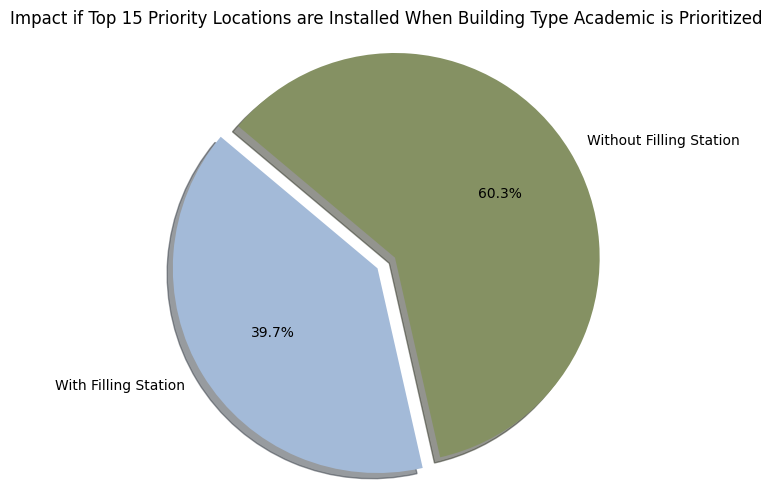

In [28]:
# Calculate the sum of 'avg_daily_density_cnt' in these top 10 rows
sum_avg_daily_density_top_x_extension = top_x_rows_extension['avg_daily_density_cnt'].sum()

# if we were to install the top 10 locations, how would the impact change?

potential_total_sum_avg_daily_density_top_x_extension = sum_avg_daily_density_top_x_extension + sum_density_for_current_inventory

sum_density_for_non_inventory_new_x_extension = total_avg_daily_density_cnt - potential_total_sum_avg_daily_density_top_x_extension

labels = 'With Filling Station', 'Without Filling Station'
sizes = [potential_total_sum_avg_daily_density_top_x_extension, sum_density_for_non_inventory_new_x_extension]
colors = ['#a3bad8', '#859163']
explode = (0.1, 0)

# Plot
plt.figure(figsize=(8, 6))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
plt.axis('equal')
plt.title(f'Impact if Top {number_proposed_locations} Priority Locations are Installed When {factor_to_prioritize} is Prioritized')
plt.show()

# **Further Analysis For Impact When Installing Top 10, 20, and 30 New Proposed Locations**

Top 10 Priority Locations To Install When Building Type Academic is Prioritized
              full_address_with_end floor
1098        890 commonwealth avenue     2
51         1010 commonwealth avenue     1
744         595 commonwealth avenue     1
453          264-270 bay state road     1
1141        949 commonwealth avenue     1
816           64-86 cummington mall     b
905   745 - 755 commonwealth avenue     1
704               53 bay state road     3
990         808 commonwealth avenue     4
454          264-270 bay state road     2


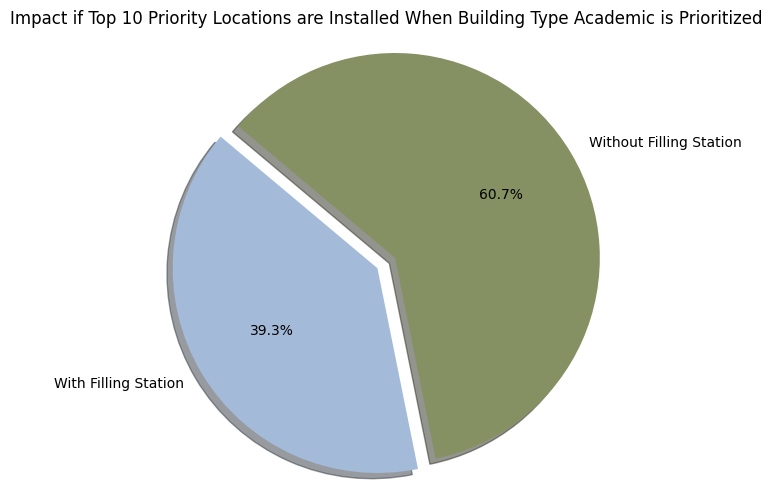

In [29]:
# Select the top 10 rows
top_10_rows_extension = result.head(10)

# Calculate the sum of 'avg_daily_density_cnt' in these top 10 rows
sum_avg_daily_density_top_10_extension = top_10_rows_extension['avg_daily_density_cnt'].sum()

# Printing the top 10 rows
print(f'Top 10 Priority Locations To Install When {factor_to_prioritize} is Prioritized')
print(top_10_rows_extension[['full_address_with_end', 'floor']])

# if we were to install the top 10 locations, how would the impact change?

potential_total_sum_avg_daily_density_top_10_extension = sum_avg_daily_density_top_10_extension + sum_density_for_current_inventory

sum_density_for_non_inventory_new_10_extension = total_avg_daily_density_cnt - potential_total_sum_avg_daily_density_top_10_extension

labels = 'With Filling Station', 'Without Filling Station'
sizes = [potential_total_sum_avg_daily_density_top_10_extension, sum_density_for_non_inventory_new_10_extension]
colors = ['#a3bad8', '#859163']
explode = (0.1, 0)

# Plot
plt.figure(figsize=(8, 6))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
plt.axis('equal')
plt.title(f'Impact if Top 10 Priority Locations are Installed When {factor_to_prioritize} is Prioritized')
plt.show()

Next 10 Priority Locations To Install When Building Type Academic is Prioritized
           full_address_with_end floor
455       264-270 bay state road     3
426           236 bay state road     b
703            53 bay state road     1
457       264-270 bay state road     5
458       264-270 bay state road     b
133         138 mountfort street     3
134         138 mountfort street     b
157           141 bay state road     b
790  617-621 commonwealth avenue     1
132         138 mountfort street     2


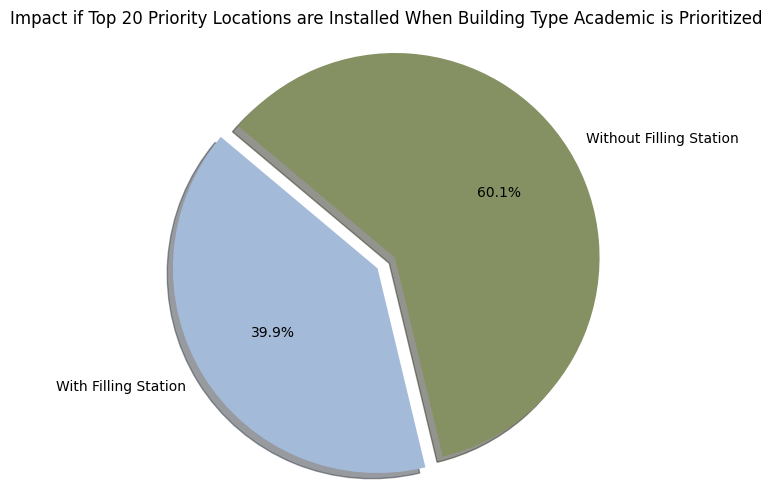

In [30]:
# Select the top 20 rows
top_20_rows_extension = result.head(20)

# Calculate the sum of 'avg_daily_density_cnt' in these top 20 rows
sum_avg_daily_density_top_20_extension = top_20_rows_extension['avg_daily_density_cnt'].sum()

# Printing the next 10 rows
last_10_rows_of_20_extension = top_20_rows_extension.tail(10)
print(f'Next 10 Priority Locations To Install When {factor_to_prioritize} is Prioritized')
print(last_10_rows_of_20_extension[['full_address_with_end', 'floor']])

# if we were to install the top 20 locations, how would the impact change?

potential_total_sum_avg_daily_density_top_20_extension = sum_avg_daily_density_top_20_extension + sum_density_for_current_inventory

sum_density_for_non_inventory_new_20_extension = total_avg_daily_density_cnt - potential_total_sum_avg_daily_density_top_20_extension

labels = 'With Filling Station', 'Without Filling Station'
sizes = [potential_total_sum_avg_daily_density_top_20_extension, sum_density_for_non_inventory_new_20_extension]
colors = ['#a3bad8', '#859163']
explode = (0.1, 0)

# Plot
plt.figure(figsize=(8, 6))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
plt.axis('equal')
plt.title(f'Impact if Top 20 Priority Locations are Installed When {factor_to_prioritize} is Prioritized')
plt.show()

Next 10 Priority Locations To Install When Building Type Academic is Prioritized
           full_address_with_end floor
456       264-270 bay state road     4
165           147 bay state road     1
155           141 bay state road     3
279           185 bay state road     4
822            67 bay state road     3
167           147 bay state road     3
284           187 bay state road     b
185           154 bay state road     b
793  617-621 commonwealth avenue     4
869      704 commonwealth avenue     5


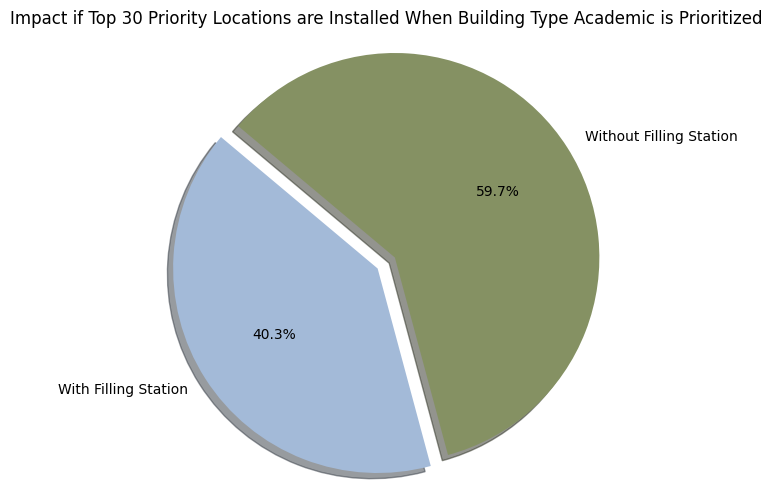

In [31]:

# Select the top 30 rows
top_30_rows_extension = result.head(30)

# Calculate the sum of 'avg_daily_density_cnt' in these top 30 rows
sum_avg_daily_density_top_30_extension = top_30_rows_extension['avg_daily_density_cnt'].sum()

# Printing the next 10 rows
last_10_rows_of_30_extension = top_30_rows_extension.tail(10)
print(f'Next 10 Priority Locations To Install When {factor_to_prioritize} is Prioritized')
print(last_10_rows_of_30_extension[['full_address_with_end', 'floor']])

# if we were to install the top 10 locations, how would the impact change?

potential_total_sum_avg_daily_density_top_30_extension = sum_avg_daily_density_top_30_extension + sum_density_for_current_inventory

sum_density_for_non_inventory_new_30_extension = total_avg_daily_density_cnt - potential_total_sum_avg_daily_density_top_30_extension

labels = 'With Filling Station', 'Without Filling Station'
sizes = [potential_total_sum_avg_daily_density_top_30_extension, sum_density_for_non_inventory_new_30_extension]
colors = ['#a3bad8', '#859163']
explode = (0.1, 0)

# Plot
plt.figure(figsize=(8, 6))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
plt.axis('equal')
plt.title(f'Impact if Top 30 Priority Locations are Installed When {factor_to_prioritize} is Prioritized')
plt.show()